# Portfolio analysis as a service: Horizon Europe projects on a policy topic

**What this is.** A short, reproducible example of the first analytical step in the approach described in the accompanying note. A policy unit asks what Horizon Europe has funded in its area; the Feedback to Policy team answers with a documented portfolio overview that the unit can check and reuse.

**What it does**
1. Downloads the public CORDIS file of Horizon Europe projects and records exactly which version was used.
2. Checks the quality of the data before using it.
3. Reads the policy unit's topic definition (an illustrative list of terms).
4. Selects the matching projects and records why each one was selected.
5. Summarises the portfolio: number of projects, EU contribution, start year, type of action, coordinator country and project status, and compares the selection with an existing classification.
6. Exports the list so that the policy unit can confirm or reject each project.

**How to read it.** Text cells explain each step in plain language. Grey cells contain the code and the result appears below each one. You do not need to read the code to follow the analysis.

**Assumption.** The topic definition in step 4 ('nature-based solutions') is illustrative. In a real request, the policy unit provides and confirms it.

## 1. Set-up
The analysis uses two common, free Python libraries: *pandas* for tables and *matplotlib* for charts. The exact versions are listed in `requirements.txt`.

In [1]:
import csv, hashlib, io, re, urllib.request, zipfile
from datetime import date
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

DATA_URL = "https://cordis.europa.eu/data/cordis-HORIZONprojects-csv.zip"
RAW_DIR = Path("data/raw")                                   # downloaded file, not stored in the repository
TOPIC_FILE = Path("inputs/topic_definition_illustrative.csv")
OUTPUT_DIR = Path("outputs")

pd.set_option("display.max_colwidth", 80)                   # show labels and titles up to 80 characters

def fmt(n):
    """Write a number with a space as thousands separator, e.g. 15 000."""
    return f"{n:,.0f}".replace(",", " ")

print("pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

pandas 3.1.1 | matplotlib 3.11.2


## 2. Get the data
**Source:** CORDIS, *EU research projects under Horizon Europe (2021-2027)*, published by the European Commission on [data.europa.eu](https://data.europa.eu/data/datasets/cordis-eu-research-projects-under-horizon-europe-2021-2027) and reused under the European Commission reuse notice.

CORDIS updates this file regularly. The notebook therefore records the download date and a digital fingerprint of the file (SHA-256): anyone using the file with the same fingerprint gets the same results.

In [2]:
RAW_DIR.mkdir(parents=True, exist_ok=True)
zip_path = RAW_DIR / "cordis-HORIZONprojects-csv.zip"
date_file = RAW_DIR / "downloaded_on.txt"

if not zip_path.exists():
    urllib.request.urlretrieve(DATA_URL, zip_path)
    date_file.write_text(date.today().isoformat())

downloaded_on = date_file.read_text() if date_file.exists() else "unknown"
print("Downloaded on:", downloaded_on)
print("File size:", round(zip_path.stat().st_size / 1e6, 1), "MB")
fingerprint = hashlib.sha256(zip_path.read_bytes()).hexdigest()
print("SHA-256 fingerprint:", fingerprint)

Downloaded on: 2026-11-12
File size: 38.3 MB
SHA-256 fingerprint: 69dc223a80864d0e6a695b3d4344a74da226a93727da564a677edcd3ed5d3f33


### Reading the files
The download contains several tables. This analysis uses two of them: `project.csv` (one row per project) and `organization.csv` (one row per organisation taking part in a project).

In a small number of rows of `project.csv`, the separator character (;) also appears inside one of the two free-text columns, the project description (`objective`) or the `keywords`, which splits the row into too many columns. The repair uses the structure of the file: the columns before the description are intact, and the date-and-time column that follows it (`contentUpdateDate`) shows where the description ends. The keywords sit between the DOI and the last two columns. The notebook reports how many rows it repaired, and step 3 checks that every repaired row has its fields in the right place. Spotting and reporting this kind of issue is part of the data-quality work of the service.

In [3]:
DATETIME = re.compile(r"\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}$")

def repair_project_row(row, header):
    """Rebuild a project row whose free-text columns contain the separator."""
    start = header.index("objective")
    end = next((j for j in range(start + 1, len(row)) if DATETIME.match(row[j])), None)
    if end is None:                                   # no date and time found: leave the row as it is
        return row
    return (row[:start] + [";".join(row[start:end])]  # the columns before, then the description
            + row[end:end + 3]                        # contentUpdateDate, rcn, grantDoi
            + [";".join(row[end + 3:-2])]             # keywords
            + row[-2:])                               # Human-validated, legalBasis

def read_cordis_table(name, repair_row=None):
    """Read one CORDIS table from the downloaded zip file, repairing split rows if a repair is given."""
    with zipfile.ZipFile(zip_path) as z:
        rows = list(csv.reader(io.StringIO(z.read(name).decode("utf-8")), delimiter=";"))
    header, body = rows[0], rows[1:]
    repaired = 0
    for k, row in enumerate(body):
        if repair_row and len(row) > len(header):
            body[k] = repair_row(row, header)
            repaired += 1
    still_wrong = sum(len(row) != len(header) for row in body)
    print(f"{name}: {fmt(len(body))} rows, {repaired} repaired, {still_wrong} still malformed")
    table = pd.DataFrame([row for row in body if len(row) == len(header)], columns=header)
    table.attrs.update(repaired=repaired, still_wrong=still_wrong)   # kept for the quality checks
    return table

projects = read_cordis_table("project.csv", repair_row=repair_project_row)
organisations = read_cordis_table("organization.csv")

project.csv: 24 419 rows, 202 repaired, 0 still malformed
organization.csv: 151 382 rows, 0 repaired, 0 still malformed


## 3. Check data quality
Before using the data, we check that it is fit for this purpose: one row per project, the fields we need are filled in, and dates and amounts are plausible. A data service should publish these checks with its results, so that users know how far to trust them.

Each check is labelled with the data-quality attribute it tests, using the attributes listed in the Commission's corporate data policy (*Data governance and data policies at the European Commission*, Secretariat-General, 2020): accuracy, completeness, consistency, uniqueness, integrity, timeliness and provenance.

*EU contribution* in this file is the **maximum EU contribution** set in the grant agreement (a commitment), not the amount paid. Some amounts are written with a decimal comma (for example `2073781,25`) and others with a decimal point; the notebook converts both and counts how many used the comma.

In [4]:
key_fields = ["title", "objective", "keywords", "startDate", "ecMaxContribution"]
missing = {f: (projects[f].str.strip() == "").sum() for f in key_fields}

# A repaired row is in place if its date-and-time column holds a date and time
out_of_place = (~projects["contentUpdateDate"].str.match(DATETIME)).sum()

projects["startDate"] = pd.to_datetime(projects["startDate"], errors="coerce")
amount_text = projects["ecMaxContribution"].str.strip()
decimal_comma = amount_text.str.contains(",", regex=False)
projects["ecMaxContribution"] = pd.to_numeric(amount_text.str.replace(",", ".", regex=False), errors="coerce")
total_billion = projects["ecMaxContribution"].sum() / 1e9

checks = pd.DataFrame(
    [("Context", "Projects in the file", fmt(len(projects))),
     ("Provenance", "Source file fingerprint (SHA-256, first 16 characters)", fingerprint[:16]),
     ("Timeliness", "Date the file was downloaded", downloaded_on),
     ("Integrity", "Rows split by the separator, repaired", fmt(projects.attrs["repaired"])),
     ("Integrity", "Rows still malformed after repair", fmt(projects.attrs["still_wrong"])),
     ("Integrity", "Rows with a field out of place", fmt(out_of_place)),
     ("Uniqueness", "Duplicate project identifiers", fmt(projects["id"].duplicated().sum()))]
    + [("Completeness", f"Projects with no '{f}'", fmt(n)) for f, n in missing.items()]
    + [("Consistency", "Earliest start date", str(projects["startDate"].min().date())),
       ("Consistency", "Latest start date", str(projects["startDate"].max().date())),
       ("Consistency", "Amounts written with a decimal comma (converted)", fmt(decimal_comma.sum())),
       ("Accuracy", "Start dates that could not be read", fmt(projects["startDate"].isna().sum())),
       ("Accuracy", "Amounts that could not be read as numbers", fmt(projects["ecMaxContribution"].isna().sum())),
       ("Accuracy", "Projects with a negative EU contribution", fmt((projects["ecMaxContribution"] < 0).sum())),
       ("Accuracy", "Total maximum EU contribution in the file (EUR billion)", f"{total_billion:.1f}")],
    columns=["Quality attribute", "Check", "Result"])
checks

,Quality attribute,Check,Result
0,Context,Projects in the file,24 419
1,Provenance,"Source file fingerprint (SHA-256, first 16 characters)",69dc223a80864d0e
2,Timeliness,Date the file was downloaded,2026-11-12
3,Integrity,"Rows split by the separator, repaired",202
4,Integrity,Rows still malformed after repair,0
5,Integrity,Rows with a field out of place,0
6,Uniqueness,Duplicate project identifiers,0
7,Completeness,Projects with no 'title',0
8,Completeness,Projects with no 'objective',0
9,Completeness,Projects with no 'keywords',2 236


**Plausibility check.** The total maximum EU contribution in the file should be of the same order as the Commission's published figure of about EUR 61 billion invested in grants under Horizon Europe so far (Horizon Europe State of Play report, announced on 29 September 2026, IP/26/2004). A much lower total would point to amounts that were not read correctly.

## 4. The topic definition (input from the policy unit)
In the approach described in the note, the policy unit fills in a short template that defines its area. Here the template is a small table of terms, each marked as **core** (clearly inside the topic) or **related** (possibly inside; the unit decides).

**The terms below are illustrative.** In a real request the policy unit provides them and confirms the result in step 7.

In [5]:
topic = pd.read_csv(TOPIC_FILE)
topic

,term,scope,note
0,nature-based solution,core,Illustrative. Also finds the plural
1,nature based solution,core,Illustrative. Spelling without a hyphen
2,green infrastructure,related,Illustrative. For the policy unit to confirm
3,blue-green infrastructure,related,Illustrative. For the policy unit to confirm
4,ecosystem restoration,related,Illustrative. For the policy unit to confirm
5,rewilding,related,Illustrative. For the policy unit to confirm
6,agroforestry,related,Illustrative. Agricultural practice often presented as nature-based
7,constructed wetland,related,Illustrative. For the policy unit to confirm
8,sponge city,related,Illustrative. For the policy unit to confirm


## 5. Select the projects, keeping the reason for each match
A project is selected when a term appears in its title, objective or keywords. Matching ignores capital letters and also finds plurals ('solution' finds 'solutions').

For every project, the notebook records which terms matched and in which fields, so that each selection can be checked. A project counts as *core* if at least one core term matched. This simple, transparent rule is a starting point; its limits are discussed in step 8.

In [6]:
FIELDS = ["title", "objective", "keywords"]
patterns = {term: re.compile(r"\b" + re.escape(term), re.IGNORECASE) for term in topic["term"]}

def why_selected(row):
    terms, fields = [], []
    for term, pattern in patterns.items():
        hits = [f for f in FIELDS if pattern.search(row[f])]
        if hits:
            terms.append(term)
            fields += [f for f in hits if f not in fields]
    return pd.Series({"matched_terms": "; ".join(terms), "matched_fields": ", ".join(fields)})

reasons = projects[FIELDS].apply(why_selected, axis=1)
selected = projects.join(reasons).query("matched_terms != ''").copy()

core_terms = set(topic.loc[topic["scope"] == "core", "term"])
selected["scope"] = selected["matched_terms"].apply(
    lambda s: "core" if core_terms & set(s.split("; ")) else "related")

print(f"{fmt(len(selected))} of {fmt(len(projects))} projects selected")
selected[["id", "acronym", "title", "scope", "matched_terms", "matched_fields"]].head(10)

224 of 24 419 projects selected


,id,acronym,title,scope,matched_terms,matched_fields
345,101044244,FISH-A,Fishing Architecture: The Ecological Continuum between Buildings and Fish Sp...,core,nature-based solution,keywords
673,101058574,MAST3RBoost,Maturing the production standards of ultraporous structures for high density...,related,agroforestry,objective
702,101059232,URBANE,One Health approaches to support agroecological transformation of peri-urban...,core,nature-based solution,keywords
723,101059957,EmpowerUs,Socio-economic Empowerment of coastal communities as users of the sea to ens...,core,nature-based solution,objective
724,101060020,NORDBALT-ECOSAFE,Nitrogen and phosphorus load reduction approach within safe ecological bound...,core,nature-based solution,objective
741,101060464,NATURANCE,"Nature for insurance, and insurance for nature",core,nature-based solution,objective
856,101061083,Invest4Nature,Promoting investments in NBS and accelerating market uptake by gaining a bet...,core,nature-based solution,objective
956,101060497,EcoAdvance,Assessing and Consolidating Recent Advances on Freshwater Ecosystem Restoration,related,ecosystem restoration,"title, objective"
963,101060525,NBS EduWORLD,Nature-Based Solutions Education Network,core,nature-based solution,title
970,101060635,REFOREST,Agroforestry at the forefront of farming sustainability in multifunctional l...,related,agroforestry,"title, objective, keywords"


## 6. Portfolio overview
### How many projects, and how much EU funding?

In [7]:
summary = selected.groupby("scope").agg(
    projects=("id", "count"),
    eu_contribution=("ecMaxContribution", "sum")).reindex(["core", "related"])
summary.loc["total"] = [len(selected), selected["ecMaxContribution"].sum()]

summary["projects"] = summary["projects"].map(fmt)
summary["eu_contribution"] = (summary["eu_contribution"] / 1e6).round(1).astype(str)
summary.rename(columns={"projects": "Projects", "eu_contribution": "Maximum EU contribution (EUR million)"})

,Projects,Maximum EU contribution (EUR million)
scope,,
core,161,909.0
related,63,244.8
total,224,1153.8


### When did the projects start?

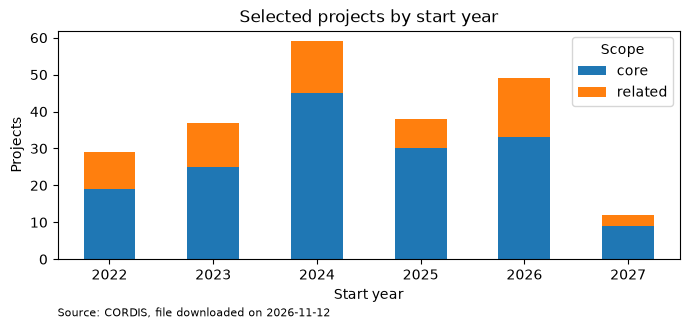

In [8]:
by_year = (selected.assign(start_year=selected["startDate"].dt.year.astype("Int64"))
           .groupby(["start_year", "scope"]).size().unstack(fill_value=0))

ax = by_year.plot(kind="bar", stacked=True, figsize=(7, 3.5), rot=0)
ax.set_xlabel("Start year")
ax.set_ylabel("Projects")
ax.set_title("Selected projects by start year")
ax.legend(title="Scope")
ax.annotate(f"Source: CORDIS, file downloaded on {downloaded_on}", xy=(0, -0.25),
            xycoords="axes fraction", fontsize=8)
plt.tight_layout()
plt.show()

### Which types of action?
The *type of action* sets what is funded and how. The most common are Research and Innovation Actions (HORIZON-RIA), Innovation Actions (HORIZON-IA) and Coordination and Support Actions (HORIZON-CSA).

In [9]:
selected["fundingScheme"].value_counts().head(8).rename_axis("Type of action").to_frame("Projects")

,Projects
Type of action,
HORIZON-IA,72
HORIZON-RIA,71
HORIZON-TMA-MSCA-PF-EF,34
HORIZON-CSA,21
HORIZON-ERC,7
HORIZON-TMA-MSCA-SE,6
HORIZON-TMA-MSCA-PF-GF,4
HORIZON-TMA-MSCA-DN,3


### Where are the coordinators based?
Country codes as published by CORDIS (for example EL for Greece).

In [10]:
coordinators = organisations.loc[organisations["role"] == "coordinator", ["projectID", "country"]]
(selected.merge(coordinators, left_on="id", right_on="projectID", how="left")["country"]
 .value_counts().head(10).rename_axis("Coordinator country").to_frame("Projects"))

,Projects
Coordinator country,
ES,34
IT,26
EL,16
DE,16
PT,15
FR,15
DK,12
UK,11
BE,10


### How many projects have finished?
Only closed projects have final results. CORDIS marks running projects as SIGNED.

In [11]:
selected["status"].value_counts().rename_axis("Project status").to_frame("Projects")

,Projects
Project status,
SIGNED,218
TERMINATED,4
CLOSED,2


### Could an existing classification do the job?
CORDIS also publishes *EU policy-priority trackers*: for each project, the share of its funding (0, 40 or 100%) counted towards EU spending targets such as climate and biodiversity. The closest to this topic is the biodiversity tracker. Comparing it with the selection shows whether the policy unit could simply reuse it.

In [12]:
trackers = read_cordis_table("policyPriorities.csv")
tracked = set(trackers.loc[trackers["biodiversity"].isin(["40", "100"]), "projectID"])
in_both = selected["id"].isin(tracked)

pd.DataFrame(
    [("Projects with a biodiversity tracker of 40% or 100%", fmt(len(tracked))),
     ("Selected projects", fmt(len(selected))),
     ("Selected projects that carry the tracker", f"{fmt(in_both.sum())} ({in_both.mean():.0%})"),
     ("Selected projects without the tracker", fmt((~in_both).sum())),
     ("Tracked projects per selected project", f"{len(tracked) / len(selected):.0f}")],
    columns=["Comparison", "Result"])

policyPriorities.csv: 118 956 rows, 0 repaired, 0 still malformed


,Comparison,Result
0,Projects with a biodiversity tracker of 40% or 100%,3 370
1,Selected projects,224
2,Selected projects that carry the tracker,160 (71%)
3,Selected projects without the tracker,64
4,Tracked projects per selected project,15


The tracker was built to follow spending, not to define a policy area: it is far broader than the selection and does not cover all of it. The boundary of the topic therefore has to be agreed with the policy unit.

## 7. Export for review by the policy unit
The selection is a proposal, not a final answer. The notebook writes it to a file that opens in a spreadsheet, with a link to each project's CORDIS page and two empty columns, *include (yes/no)* and *comment*.

The policy unit reviews the list. The share of projects it keeps shows how precise the topic definition is. The reviewed list then becomes the reference against which any later improvement, including AI-assisted search, is measured (see section 3 of the note).

In [13]:
OUTPUT_DIR.mkdir(exist_ok=True)
review = selected[["id", "acronym", "title", "startDate", "status", "ecMaxContribution",
                   "scope", "matched_terms", "matched_fields"]].copy()
review["startDate"] = review["startDate"].dt.date
review["cordis_page"] = "https://cordis.europa.eu/project/id/" + review["id"]
review["include (yes/no)"] = ""
review["comment"] = ""
review = review.sort_values(["scope", "startDate"])

out_file = OUTPUT_DIR / "projects_for_review.csv"
review.to_csv(out_file, index=False, encoding="utf-8-sig")    # utf-8-sig keeps accents readable in Excel
print(f"{fmt(len(review))} projects written to {out_file}")

224 projects written to outputs\projects_for_review.csv


## 8. Limitations and next steps
- **Words, not meaning.** Matching on terms misses projects that describe the same idea in other words, and picks up some that use a term in another sense. The policy unit's review in step 7 measures both.
- **Funding, not results.** This file describes what was funded. Results (deliverables, publications, report summaries) are published in separate CORDIS files, and many projects are still running, so any view of results will be partial.
- **One moment in time.** The figures reflect the file downloaded on the date shown in step 2.
- **Commitments, not payments.** EU contribution is the maximum set in the grant agreement.

**Next steps**
1. Refine the terms with the policy unit and agree the boundary between core and related.
2. Compare the selection with the classification of science fields (EuroSciVoc) included in the same download.
3. Add the results files for closed projects.
4. Test whether AI-assisted search finds relevant projects that the terms miss, using the reviewed list as the benchmark and keeping a person responsible for every inclusion (see section 3 of the note).